# LDA Baseline Model — Page Level
**Modeling**

Implements a Latent Dirichlet Allocation (LDA) baseline following the CRISP-DM modeling phase.  
Library: `gensim` (Variational Bayes).  
Input: page-level token lists produced by `src/utils.py`.  
Granularity: one document = one slide page (≥ 10 tokens after preprocessing).  
Split: 90/10 holdout (108 train / 13 test, `random_state=42`).

**Structure:**
1. Setup & Data Loading
2. Corpus Preparation (dictionary + BoW + train/test split)
3. Model Training
4. Topic Inspection
5. Initial Evaluation (C_v)
6. Grid Search — Finding the Best K
7. Cross-library Comparison
8. Final Evaluation (C_v, perplexity, diversity, cosine similarity, entropy, exclusivity)

## 1. Setup & Data Loading

In [23]:
import os
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

_nb_dir = os.path.dirname(os.path.abspath('lda.ipynb'))
_src_dir = os.path.abspath(os.path.join(_nb_dir, '..'))
if _src_dir not in sys.path:
    sys.path.insert(0, _src_dir)

warnings.filterwarnings('ignore')

# Plotting defaults
plt.rcParams.update({
    'figure.dpi'       : 130,
    'axes.spines.top'  : False,
    'axes.spines.right': False,
    'axes.titlesize'   : 13,
    'axes.labelsize'   : 11,
    'font.family'      : 'serif',
})
PALETTE = ['#2C5F8A', '#4C9BE8', '#A8C8E8', '#D9E8F5']

print('Libraries loaded.')

Libraries loaded.


In [24]:
from utils import load_corpus, tokenize_corpus, build_slide_page_docs

# Load and Tokenize corpus
corpus = tokenize_corpus(load_corpus())

# Aggregate to page level. Drop pages with fewer than 10 tokens
MIN_TOKENS = 10
docs = build_slide_page_docs(corpus)
docs = docs[docs['n_tokens'] >= MIN_TOKENS].reset_index(drop=True)

print(f'Documents (pages): {len(docs)}')
print(f'Token count — min: {docs.n_tokens.min()}, median: {docs.n_tokens.median():.0f}, max: {docs.n_tokens.max()}')
docs.head()

Dropping 6 empty pages after tokenisation.


Documents (pages): 121
Token count — min: 10, median: 21, max: 69


,source_file,page,tokens,n_tokens
0,icd_1_v1_cleaned_v7.csv,5,"[logístico, conteúdo, informação, plataforma, ...",24
1,icd_1_v1_cleaned_v7.csv,6,"[unidade, curricular, objetivo, contacto, ciên...",39
2,icd_1_v1_cleaned_v7.csv,7,"[processo, pedagógico, aplicação, prático, est...",26
3,icd_1_v1_cleaned_v7.csv,8,"[sucesso, capaz, necessidade, existência, prát...",27
4,icd_1_v1_cleaned_v7.csv,9,"[avaliação, avaliação, periódico, modalidade, ...",33


In [25]:
print(f"Documents: {len(docs)}")
print(f"Total tokens: {docs.n_tokens.sum()}")
print(f"Mean tokens per document: {docs.n_tokens.mean():.1f}")
print(f"Median tokens per document: {docs.n_tokens.median():.1f}")
print(f"Min tokens: {docs.n_tokens.min()}")
print(f"Max tokens: {docs.n_tokens.max()}")

Documents: 121
Total tokens: 2894
Mean tokens per document: 23.9
Median tokens per document: 21.0
Min tokens: 10
Max tokens: 69


## 2. Corpus Preparation

In [26]:
import gensim
import gensim.corpora as corpora
from gensim.models import CoherenceModel

RANDOM_SEED = 42

texts = docs['tokens'].tolist()

# Conservative thresholds to suit the small corpus (121 docs)
dictionary = corpora.Dictionary(texts)
dictionary.filter_extremes(no_below=2, no_above=0.8)
dictionary.compactify()

bow_corpus = [dictionary.doc2bow(text) for text in texts]

print(f'Vocabulary size (after filtering): {len(dictionary)}')
print(f'Corpus size: {len(bow_corpus)} documents')
print(f'gensim version: {gensim.__version__}')

Vocabulary size (after filtering): 419
Corpus size: 121 documents
gensim version: 4.4.0


In [27]:
from sklearn.model_selection import train_test_split

# 90/10  split — model trained only on train set;
train_docs, test_docs = train_test_split(docs, test_size=0.10, random_state=RANDOM_SEED)
train_docs = train_docs.reset_index(drop=True)
test_docs  = test_docs.reset_index(drop=True)

train_texts = train_docs['tokens'].tolist()
test_texts = test_docs['tokens'].tolist()

dictionary = corpora.Dictionary(train_texts)
dictionary.filter_extremes(no_below=2, no_above=0.8)
dictionary.compactify()

bow_corpus = [dictionary.doc2bow(text) for text in train_texts]
test_bow_corpus = [dictionary.doc2bow(text) for text in test_texts]

print(f'Train: {len(train_texts)} docs | Test: {len(test_texts)} docs')

Train: 108 docs | Test: 13 docs


## 3. Model Training

In [28]:
from gensim.models import LdaModel

NUM_TOPICS  = 9     # initial number of topics for LDA; based on number of slide decks
PASSES      = 20
ITERATIONS  = 400
ALPHA       = 0.1   # symmetric Dirichlet prior on document-topic to match tomotopy default
ETA         = 0.01  # symmetric Dirichlet prior on topic-word to match tomotopy default

lda = LdaModel(
    corpus           = bow_corpus,
    id2word          = dictionary,
    num_topics       = NUM_TOPICS,
    passes           = PASSES,
    iterations       = ITERATIONS,
    alpha            = ALPHA,
    eta              = ETA,
    random_state     = RANDOM_SEED,
    per_word_topics  = True,
)

print(f'LDA trained: {NUM_TOPICS} topics, {PASSES} passes, seed={RANDOM_SEED}')
print(f'Vocabulary size: {lda.num_terms} terms')

LDA trained: 9 topics, 20 passes, seed=42
Vocabulary size: 373 terms


## 4. Topic Inspection

In [29]:
# Top terms per topic
TOP_N = 10
for i, topic in lda.print_topics(num_topics=NUM_TOPICS, num_words=TOP_N):
    print(f'Topic {i+1}: {topic}')

Topic 1: 0.086*"modelo" + 0.028*"resultado" + 0.026*"aprendizagem" + 0.026*"avaliação" + 0.022*"classificação" + 0.019*"cliente" + 0.017*"algoritmo" + 0.016*"erro" + 0.015*"objetivo" + 0.014*"regressão"
Topic 2: 0.045*"processo" + 0.030*"ciência" + 0.026*"correlação" + 0.023*"conjunto" + 0.021*"variável" + 0.019*"amostra" + 0.019*"análise" + 0.017*"objetivo" + 0.015*"comum" + 0.015*"logístico"
Topic 3: 0.055*"informação" + 0.044*"treino" + 0.044*"conjunto" + 0.035*"teste" + 0.029*"modelo" + 0.024*"fonte" + 0.024*"sequência" + 0.016*"conhecimento" + 0.016*"set" + 0.016*"modo"
Topic 4: 0.058*"direito" + 0.035*"europeu" + 0.032*"objetivo" + 0.029*"estudante" + 0.029*"pessoal" + 0.029*"proteção" + 0.029*"privacidade" + 0.023*"regulamento" + 0.023*"recolha" + 0.023*"titulares"
Topic 5: 0.046*"valores" + 0.046*"cluster" + 0.037*"omisso" + 0.032*"distância" + 0.032*"informação" + 0.030*"passo" + 0.023*"média" + 0.023*"padrão" + 0.023*"clustering" + 0.021*"tratamento"
Topic 6: 0.067*"atributo"

In [30]:
from utils import generate_topic_labels_llm

TOPIC_LABELS = generate_topic_labels_llm(lda, NUM_TOPICS)

for i, label in TOPIC_LABELS.items():
    print(f'T{i+1}: {label}')

T1: Modelagem supervisionada
T2: Introdução à Ciência de Dados
T3: Modelagem Supervisionada
T4: Ética proteção dados
T5: Agrupamento e Preprocessamento
T6: Modelagem Supervisada Imagem
T7: Visualização e análise de dados
T8: Modelo generativo inteligência
T9: Modelação supervisionada


In [31]:
# Topic summary table
rows = []
for i in range(NUM_TOPICS):
    terms = lda.show_topic(i, topn=TOP_N)
    top_words_list = [w for w, _ in terms]
    top_words = ', '.join(top_words_list)
    top_weights = [round(p, 3) for _, p in terms]
    rows.append({
        'Topic': f'T{i+1}',
        'Label': TOPIC_LABELS[i],
        'Top 10 words': top_words,
        'Top word': top_words_list[0],
        'Max weight': max(top_weights),
    })

topic_df = pd.DataFrame(rows).set_index('Topic')

topic_df.style \
    .set_caption('LDA Topics — Top 10 words per Topic (Library: gensim)') \
    .set_properties(**{'text-align': 'left'}) \
    .bar(subset=['Max weight'], color="#0156AB", vmin=0, vmax=0.15)

,Label,Top 10 words,Top word,Max weight
Topic,,,,
T1,Modelagem supervisionada,"modelo, resultado, aprendizagem, avaliação, classificação, cliente, algoritmo, erro, objetivo, regressão",modelo,0.086000
T2,Introdução à Ciência de Dados,"processo, ciência, correlação, conjunto, variável, amostra, análise, objetivo, comum, logístico",processo,0.045000
T3,Modelagem Supervisionada,"informação, treino, conjunto, teste, modelo, fonte, sequência, conhecimento, set, modo",informação,0.055000
T4,Ética proteção dados,"direito, europeu, objetivo, estudante, pessoal, proteção, privacidade, regulamento, recolha, titulares",direito,0.058000
T5,Agrupamento e Preprocessamento,"valores, cluster, omisso, distância, informação, passo, média, padrão, clustering, tratamento",valores,0.046000
T6,Modelagem Supervisada Imagem,"atributo, classificação, imagem, aluno, processo, rótulo, gráfico, árvore, registo, image",atributo,0.067000
T7,Visualização e análise de dados,"visualização, informação, contexto, conhecimento, numérico, análise, modelo, resultado, projeto, apresentação",visualização,0.075000
T8,Modelo generativo inteligência,"outlier, modelo, padrão, valores, generativo, artificial, inteligência, atributo, análise, conteúdo",outlier,0.039000
T9,Modelação supervisionada,"variável, categórico, numérico, target, regressão, features, análise, problema, analytics, fit",variável,0.111000


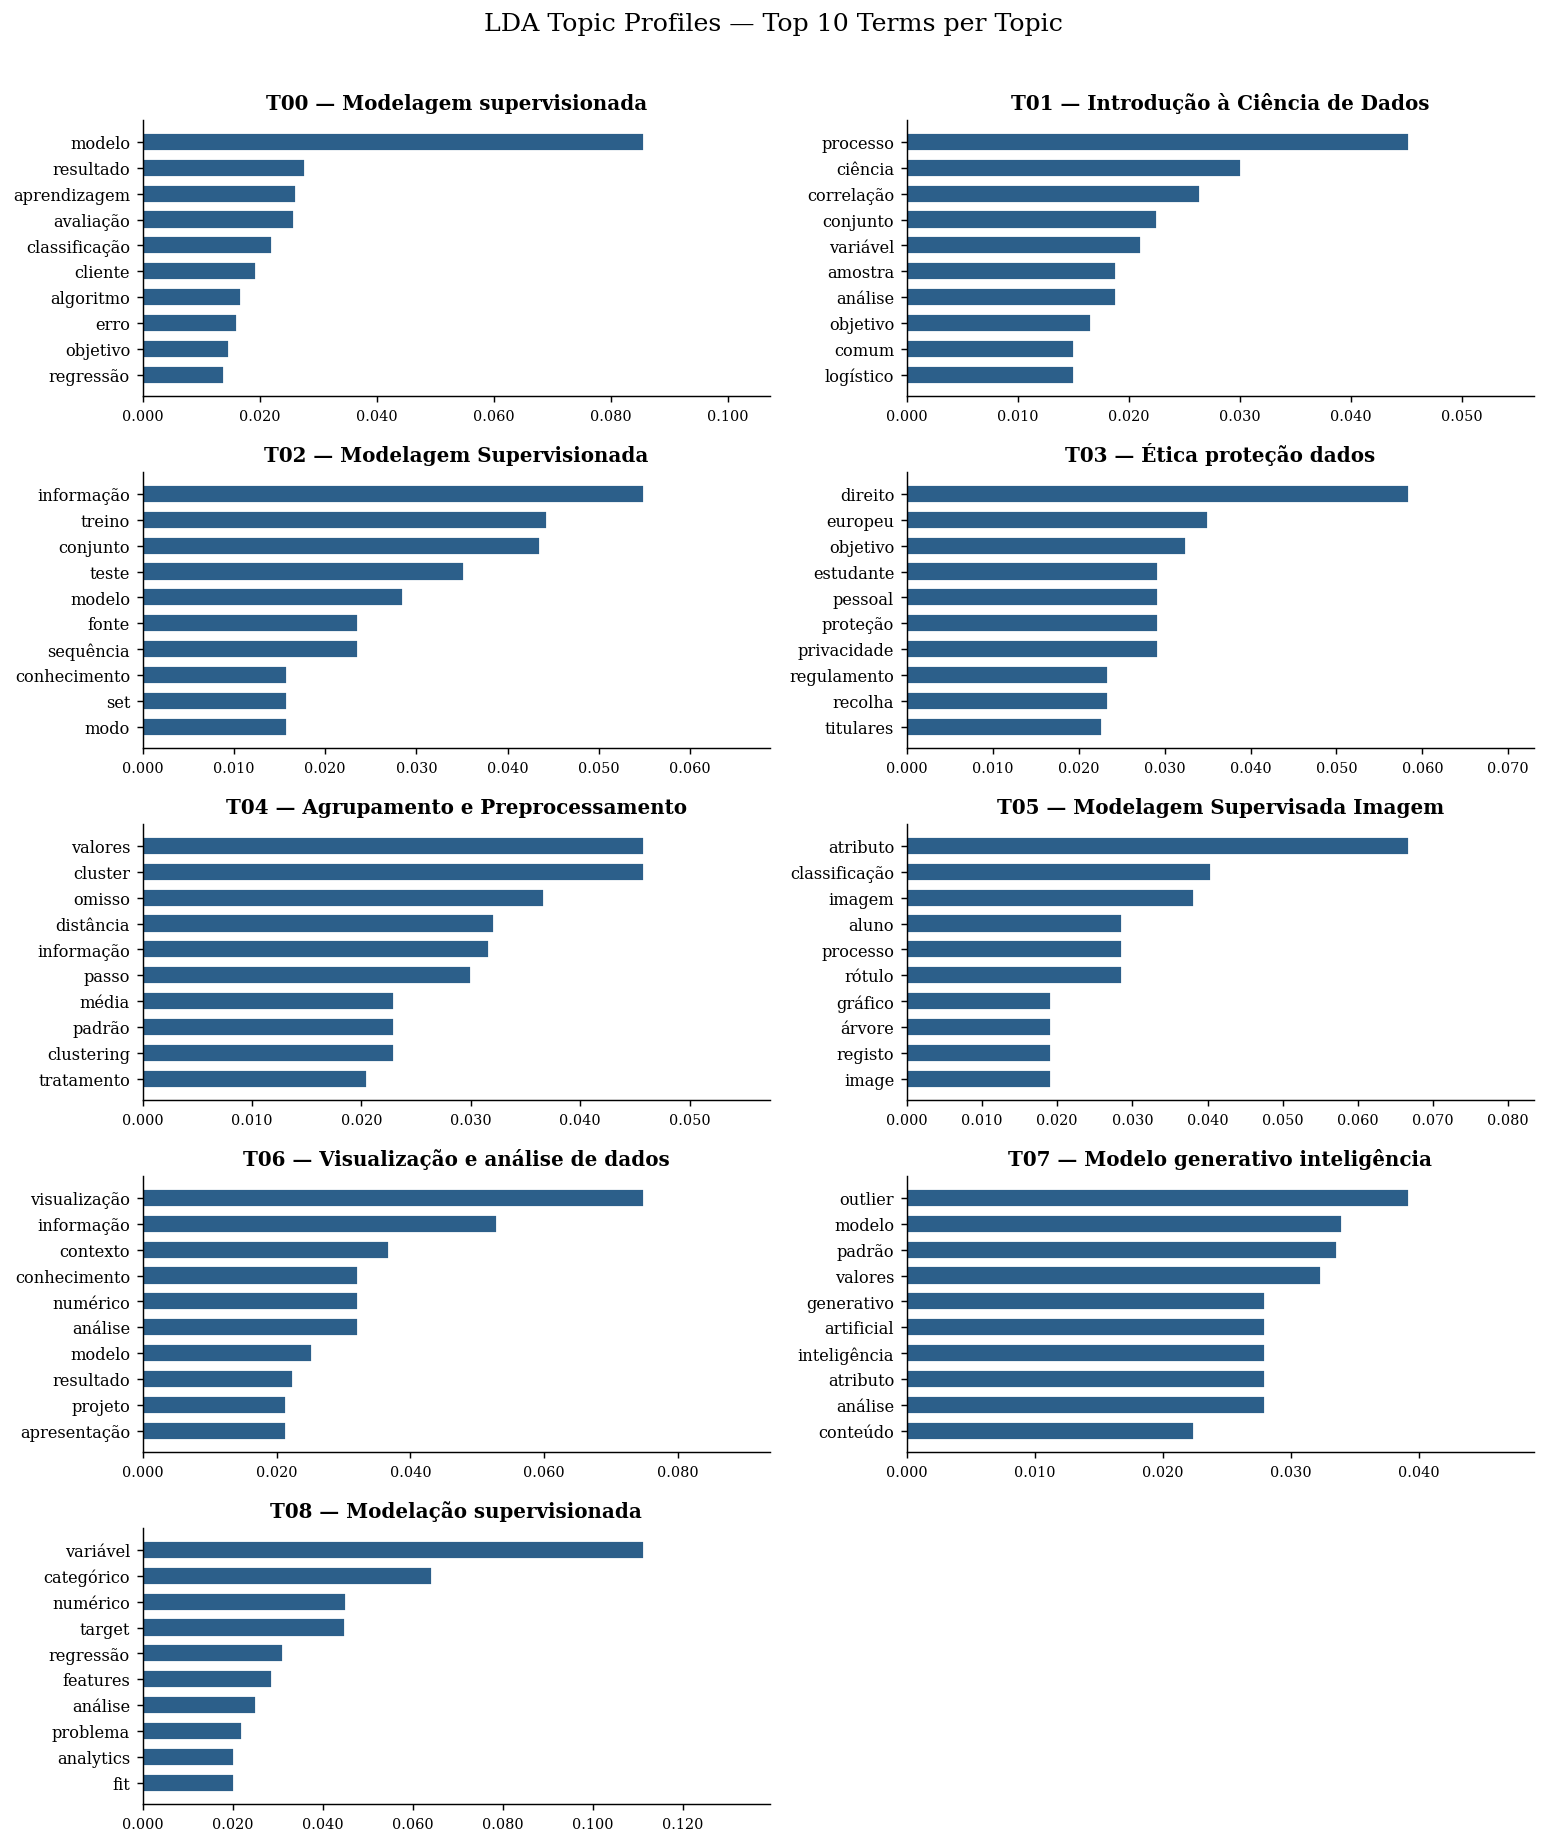

In [32]:
# Visualize topic profiles

TOP_VIS = 10
n_cols = 2
n_rows = (NUM_TOPICS + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(12, n_rows * 2.8))
axes = axes.flatten()

for i in range(NUM_TOPICS):
    terms = lda.show_topic(i, topn=TOP_VIS)
    words   = [w for w, _ in terms][::-1]
    weights = [p for _, p in terms][::-1]

    ax = axes[i]
    ax.barh(words, weights, color=PALETTE[0], edgecolor='white', height=0.7)
    ax.set_title(f'T{i:02d} — {TOPIC_LABELS[i]}', fontsize=11, fontweight='bold')
    ax.set_xlim(0, max(weights) * 1.25)
    ax.tick_params(axis='y', labelsize=9)
    ax.tick_params(axis='x', labelsize=8)
    ax.xaxis.set_major_formatter(mticker.FormatStrFormatter('%.3f'))

# hide unused subplots
for j in range(NUM_TOPICS, len(axes)):
    axes[j].set_visible(False)

fig.suptitle('LDA Topic Profiles — Top 10 Terms per Topic', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

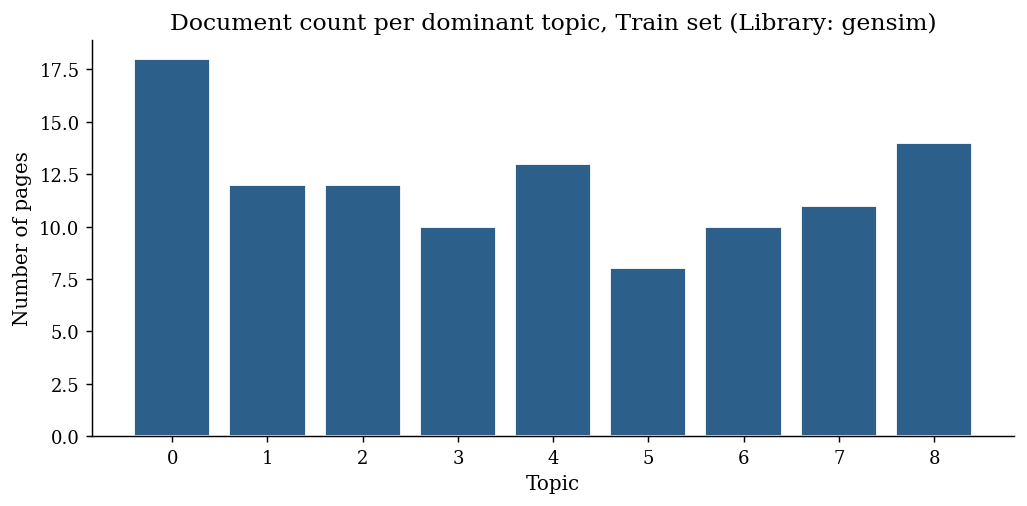

In [33]:
# Visualize document-topic distribution (Train)
train_docs_plot = train_docs.copy()
train_docs_plot['dominant_topic'] = [
    max(lda.get_document_topics(b), key=lambda x: x[1])[0] if lda.get_document_topics(b) else -1
    for b in bow_corpus
]

topic_dist = train_docs_plot['dominant_topic'].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(topic_dist.index, topic_dist.values, color=PALETTE[0], edgecolor='white')
ax.set_xlabel('Topic')
ax.set_ylabel('Number of pages')
ax.set_title('Document count per dominant topic, Train set (Library: gensim)')
ax.set_xticks(range(NUM_TOPICS))
plt.tight_layout()
plt.show()

## 5. Initial Evaluation (C_v)

In [34]:
coherence_model = CoherenceModel(
    model=lda,
    texts=train_texts,
    dictionary=dictionary,
    coherence='c_v',
)
coherence_cv = coherence_model.get_coherence()

print(f'Coherence (C_v): {coherence_cv:.4f}  (target > 0.50)')

Coherence (C_v): 0.3778  (target > 0.50)


## 6. Grid Search — Finding the Best K

K initial = 9 (one per slide deck, domain-informed prior).  
Grid search over K ∈ [3, 20] to find the C_v-optimal K for this library.  
The best K from each library will be used in the cross-library comparison (Section 7).

k= 2  C_v=0.4028
k= 3  C_v=0.4376
k= 4  C_v=0.3683
k= 5  C_v=0.3447
k= 6  C_v=0.3962
k= 7  C_v=0.3559
k= 8  C_v=0.3762
k= 9  C_v=0.3778
k=10  C_v=0.3843
k=11  C_v=0.3809
k=12  C_v=0.3932


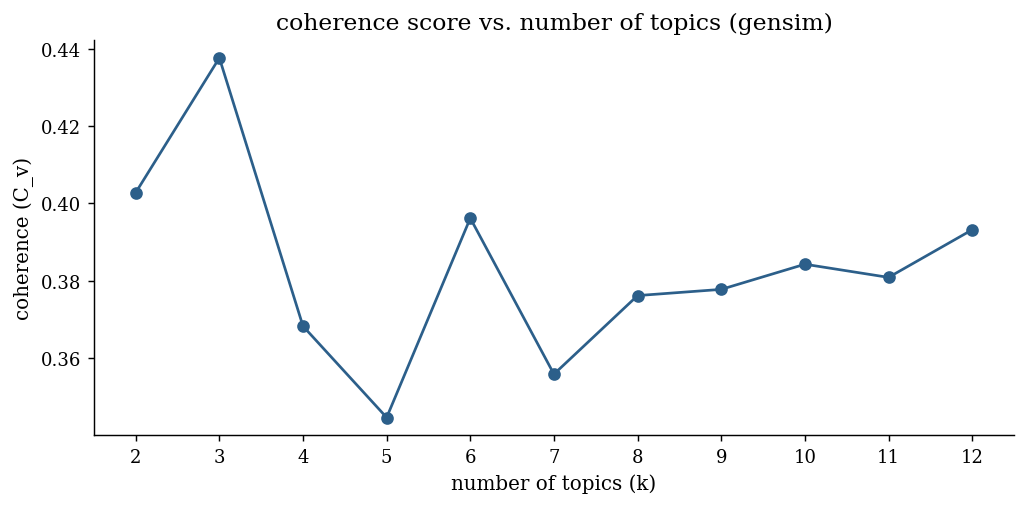


Best k=3  C_v=0.4376


In [35]:
# Coherence grid search over number of topics
# Helps to find the optimal K before committing to a final model and parameters.

TOPIC_RANGE = range(2, 13)   # Aligned with tomotopy grid search in lda_v2.ipynb

results = []
for k in TOPIC_RANGE:
    m = LdaModel(
        corpus       = bow_corpus,
        id2word      = dictionary,
        num_topics   = k,
        passes       = PASSES,
        iterations   = ITERATIONS,
        alpha        = ALPHA,
        eta          = ETA,
        random_state = RANDOM_SEED,
    )
    cv = CoherenceModel(model=m, texts=train_texts, dictionary=dictionary, coherence='c_v').get_coherence()
    results.append({'k': k, 'coherence_cv': round(cv, 4)})
    print(f'k={k:2d}  C_v={cv:.4f}')

results_df = pd.DataFrame(results)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(results_df['k'], results_df['coherence_cv'], marker='o', color=PALETTE[0])
ax.set_xlabel('number of topics (k)')
ax.set_ylabel('coherence (C_v)')
ax.set_title('coherence score vs. number of topics (gensim)')
ax.set_xticks(list(TOPIC_RANGE))
plt.tight_layout()
plt.show()

best = results_df.loc[results_df['coherence_cv'].idxmax()]
print(f'\nBest k={int(best.k)}  C_v={best.coherence_cv}')

## 7. Cross-library Comparison

Trains models at three K values to compare how each library responds to K choices made by the other:
- **K_INITIAL**: domain-informed starting point
- **K_CGS_BEST**: optimal K found by tomotopy CGS grid search
- **K_VB_BEST**: optimal K found by gensim VB grid search

In [36]:
K_INITIAL  = 9   # domain-informed prior: one topic per slide deck
K_CGS_BEST = 8   # tomotopy CGS grid search optimum (C_v peak)
K_VB_BEST  = 3   # gensim VB grid search optimum (C_v peak)

K_GRID = [K_INITIAL, K_CGS_BEST, K_VB_BEST]

models_by_k = {}
for k in K_GRID:
    m = LdaModel(
        corpus       = bow_corpus,
        id2word      = dictionary,
        num_topics   = k,
        passes       = PASSES,
        iterations   = ITERATIONS,
        alpha        = ALPHA,
        eta          = ETA,
        random_state = RANDOM_SEED,
    )
    models_by_k[k] = m
    cv = CoherenceModel(model=m, texts=train_texts, dictionary=dictionary, coherence='c_v').get_coherence()
    print(f'Trained gensim VB  k={k}  C_v={cv:.4f}')

print('\nCross-library C_v summary:')
for label, k in [('K_INITIAL', K_INITIAL), ('K_CGS_BEST', K_CGS_BEST), ('K_VB_BEST', K_VB_BEST)]:
    cv = CoherenceModel(model=models_by_k[k], texts=train_texts, dictionary=dictionary, coherence='c_v').get_coherence()
    print(f'  {label} (k={k}): C_v = {cv:.4f}')

Trained gensim VB  k=9  C_v=0.3778
Trained gensim VB  k=8  C_v=0.3762
Trained gensim VB  k=3  C_v=0.4376

Cross-library C_v summary:
  K_INITIAL (k=9): C_v = 0.3778
  K_CGS_BEST (k=8): C_v = 0.3762
  K_VB_BEST (k=3): C_v = 0.4376


## 8. Final Evaluation

Evaluates the best model found by the grid search (K_VB_BEST=3) with all metrics:
- **C_v coherence** (primary)
- **Test perplexity** (secondary)

In [42]:
best_model = models_by_k[K_VB_BEST]

# C_v coherence
best_cv = CoherenceModel(model=best_model, texts=train_texts, dictionary=dictionary, coherence='c_v').get_coherence()
print(f'Best model (k={K_VB_BEST}) — C_v: {best_cv:.4f}')

# Train perplexity — gensim native (in-sample)
train_perplexity = np.exp(-best_model.log_perplexity(bow_corpus))
print(f'Best model (k={K_VB_BEST}) — Train Perplexity: {train_perplexity:.2f}')

# Test perplexity — gensim VB variational bound (not directly comparable with CGS test perplexity)
per_word_bound  = best_model.log_perplexity(test_bow_corpus)
test_perplexity = np.exp(-per_word_bound)
print(f'Best model (k={K_VB_BEST}) — Test Perplexity: {test_perplexity:.2f}  (variational bound; not comparable with CGS)')

Best model (k=3) — C_v: 0.4376
Best model (k=3) — Train Perplexity: 990.49
Best model (k=3) — Test Perplexity: 6281732958.55  (variational bound; not comparable with CGS)


### 8.1 U_mass Coherence

In [43]:
from gensim.models import CoherenceModel

cm_umass = CoherenceModel(
    model=best_model,
    corpus=bow_corpus,
    dictionary=dictionary,
    coherence='u_mass',
)
coherence_umass = cm_umass.get_coherence()

print(f'Best model (k={K_VB_BEST}) — U_mass: {coherence_umass:.4f}  (closer to 0 = better; range typically −14 to 0)')

Best model (k=3) — U_mass: -11.6249  (closer to 0 = better; range typically −14 to 0)


In [45]:
# Topic diversity: fraction of unique words across top-N words of all topics
# Dieng et al. (2020) — range [0, 1]; higher = less redundancy between topics
TOP_N_DIV = 25

all_top_words = []
for i in range(K_VB_BEST):
    terms = best_model.show_topic(i, topn=TOP_N_DIV)
    all_top_words.extend([w for w, _ in terms])

diversity = len(set(all_top_words)) / len(all_top_words)
print(f'Best model (k={K_VB_BEST}) — Topic Diversity (top-{TOP_N_DIV}): {diversity:.4f}  (range 0–1; higher = more diverse)')

Best model (k=3) — Topic Diversity (top-25): 0.8000  (range 0–1; higher = more diverse)


In [46]:
# Mean pairwise cosine similarity over top-N topic word-probability vectors
# Lower = more distinct topics; range [0, 1]
from itertools import combinations
import numpy as np

TOP_N_COS = 10
vocab_size = len(dictionary)

# Build topic vectors (full vocab, probability at each position)
topic_vectors = []
for i in range(K_VB_BEST):
    vec = np.zeros(vocab_size)
    for w, p in best_model.show_topic(i, topn=TOP_N_COS):
        if w in dictionary.token2id:
            vec[dictionary.token2id[w]] = p
    topic_vectors.append(vec)

sims = []
for a, b in combinations(topic_vectors, 2):
    cos = np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-10)
    sims.append(cos)

mean_cos = np.mean(sims)
max_cos  = np.max(sims)
print(f'Best model (k={K_VB_BEST}) — Cosine Similarity (top-{TOP_N_COS}): mean={mean_cos:.4f}, max={max_cos:.4f}  (lower = more distinct)')

Best model (k=3) — Cosine Similarity (top-10): mean=0.1739, max=0.2954  (lower = more distinct)


In [48]:
# Shannon entropy of topic-word distributions
# Higher = more diffuse topic; lower = more concentrated/specific
from scipy.stats import entropy as shannon_entropy

entropies = []
for i in range(K_VB_BEST):
    probs = best_model.get_topics()[i]  # full vocab distribution, shape (vocab_size,)
    probs = probs / probs.sum()
    entropies.append(shannon_entropy(probs))

mean_ent = np.mean(entropies)
print(f'Best model (k={K_VB_BEST}) — Shannon Entropy: mean={mean_ent:.4f}  (higher = more diffuse)')
for i, e in enumerate(entropies):
    print(f'  T{i+1}: {e:.4f}')

Best model (k=3) — Shannon Entropy: mean=5.1348  (higher = more diffuse)
  T1: 5.2175
  T2: 5.2331
  T3: 4.9540


In [49]:
# Exclusivity: mean P(topic|word) over top-N words per topic
# Higher = words concentrated in that topic alone; lower = words shared across topics
TOP_N_EXC = 10

# Compute P(word|topic) matrix for all topics
topic_word_matrix = best_model.get_topics()  # shape (k, vocab_size)
# P(topic|word) via Bayes: normalise across topics for each word
topic_given_word = topic_word_matrix / (topic_word_matrix.sum(axis=0, keepdims=True) + 1e-10)

exclusivities = []
for i in range(K_VB_BEST):
    top_indices = topic_word_matrix[i].argsort()[-TOP_N_EXC:]
    excl = topic_given_word[i, top_indices].mean()
    exclusivities.append(excl)

mean_excl = np.mean(exclusivities)
print(f'Best model (k={K_VB_BEST}) — Exclusivity (top-{TOP_N_EXC}): mean={mean_excl:.4f}  (higher = more exclusive)')
for i, e in enumerate(exclusivities):
    print(f'  T{i+1}: {e:.4f}')

Best model (k=3) — Exclusivity (top-10): mean=0.6261  (higher = more exclusive)
  T1: 0.6544
  T2: 0.6156
  T3: 0.6084


### 8.6 Evaluation Summary

In [55]:
summary = {
    'Metric': ['C_v', 'U_mass', 'Train Perplexity', 'Test Perplexity',
               'Diversity (top-25)', 'Cosine Sim (mean)', 'Shannon Entropy', 'Exclusivity (top-10)'],
    'VB k=3': [f'{best_cv:.2f}', f'{coherence_umass:.2f}', f'{train_perplexity:.2f}',
               '6.28e+09 (†)', f'{diversity:.2f}', f'{mean_cos:.3f}',
               f'{mean_ent:.2f}', f'{mean_excl:.2f}'],
    'Direction': ['higher', 'closer to 0', 'lower', 'lower', 'higher', 'lower', 'lower', 'higher'],
}

summary_df = pd.DataFrame(summary).set_index('Metric')
summary_df.style.set_caption('† VB test perplexity uses variational bound — not comparable with CGS')

,VB k=3,Direction
Metric,,
C_v,0.44,higher
U_mass,-11.62,closer to 0
Train Perplexity,990.49,lower
Test Perplexity,6.28e+09 (†),lower
Diversity (top-25),0.80,higher
Cosine Sim (mean),0.174,lower
Shannon Entropy,5.13,lower
Exclusivity (top-10),0.63,higher
